In [ ]:
import os

import src.content_based as cb
cbr = cb.ContentBasedRec(rating_like_threshold=3.5)
from sklearn.model_selection import train_test_split
import pandas as pd

train_parts = []
test_parts = []

for user_id, user_ratings in ratings.groupby("userId"):
    train, test = train_test_split(
        user_ratings,
        test_size=0.3,
        random_state=42
    )

    train_parts.append(train)
    test_parts.append(test)

train_ratings = pd.concat(train_parts).reset_index(drop=True)
test_ratings = pd.concat(test_parts).reset_index(drop=True)

print(len(train_ratings))
print(len(test_ratings))
cbr.train(movies_data=movies, ratings=train_ratings, embeddings_precomputed=False)
user_id = 1
relevance_threshold = 3.5
top_k = 1000

user_test = test_ratings[
    test_ratings["userId"] == user_id
    ]

relevant_movies = set(
    user_test[
        user_test["rating"] >= relevance_threshold
        ]["movieId"]
)

print(relevant_movies)
recommendations = cbr.recommend(user_id, top_k=top_k)

# Evaluation

In [1]:

import pandas as pd

links = pd.read_csv("../resources/ml-latest-small/links.csv")
tags = pd.read_csv("../resources/ml-latest-small/tags.csv")
movies = pd.read_csv("../resources/ml-latest-small/movies.csv")
ratings = pd.read_csv("../resources/ml-latest-small/ratings.csv")

## Precompute embeddings (used for diversity computation)

In [2]:
from embeddings import compute_movie_embeddings

movies = compute_movie_embeddings(movies_data=movies)

/home/taras-hamkalo/repositories/code/ddw/hamkatar/06/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 14012.76it/s]


## Content based recommender

In [25]:
import src.content_based as cb
import src.evaluation as eval
from importlib import reload
reload(cb)
reload(eval)

cbr = cb.ContentBasedRec(rating_like_threshold=3.5)
res = eval.evaluate(
    recommender=cbr,
    movies_data=movies,
    ratings_data=ratings,
    relevance_threshold=3.5,
    test_size_per_user=0.3,
    seed=42
)

res

{'train_size': 70316,
 'test_size': 30520,
 'dropped_user_ids': [np.int64(54),
  np.int64(150),
  np.int64(214),
  np.int64(333),
  np.int64(442)],
 'below_required_recommendations': 0,
 'train_duration': datetime.timedelta(microseconds=125629),
 'query_time_500': datetime.timedelta(microseconds=25471),
 'ks': [1, 3, 5, 10, 15, 25, 35, 50, 100, 500],
 'precision': [np.float64(0.05289256198347107),
  np.float64(0.03140495867768595),
  np.float64(0.030082644628099172),
  np.float64(0.02710743801652892),
  np.float64(0.024022038567493114),
  np.float64(0.021619834710743805),
  np.float64(0.019976387249114522),
  np.float64(0.01821487603305785),
  np.float64(0.015702479338842976),
  np.float64(0.010482644628099174)],
 'recall': [np.float64(0.003793742100834969),
  np.float64(0.006562930288375577),
  np.float64(0.01025008950995383),
  np.float64(0.019011325591177575),
  np.float64(0.025558699319972806),
  np.float64(0.03869024202322522),
  np.float64(0.047866573836225994),
  np.float64(0.06

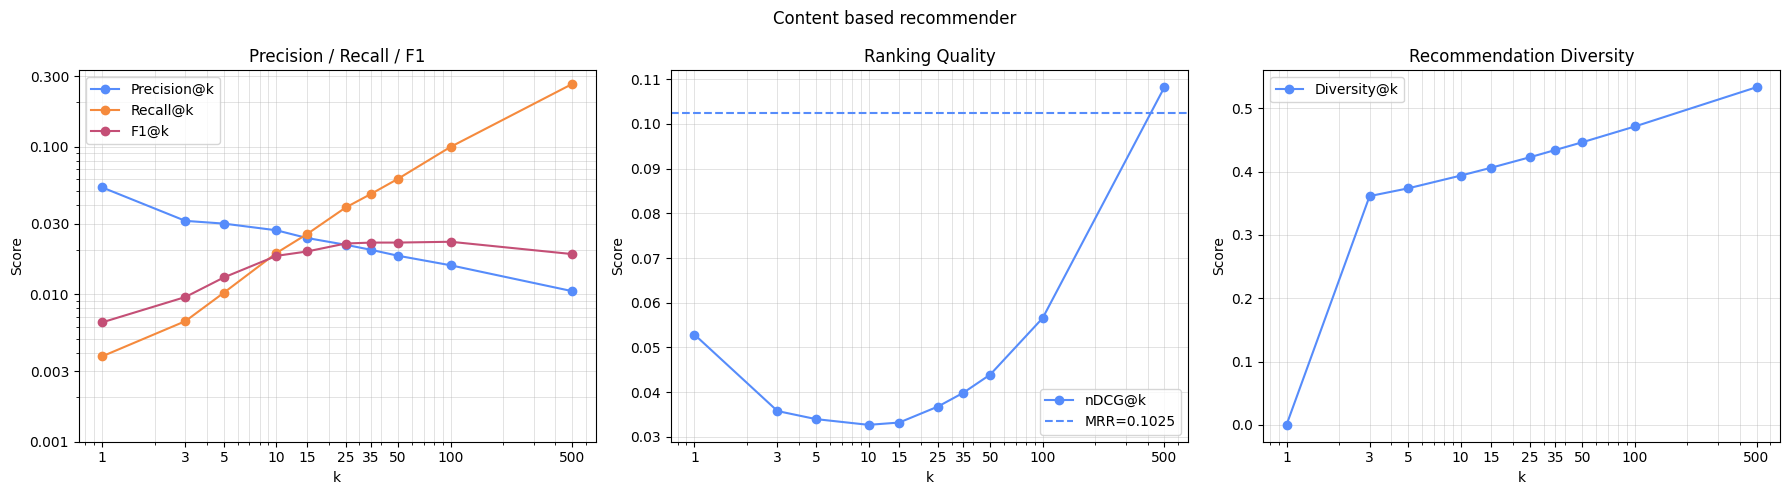

In [26]:

reload(eval)

eval.plot_results_2(results=res, title="Content based recommender")


## Collab filtering recommender

In [27]:
import src.collaborative_filtering as cf

import src.evaluation as eval
from importlib import reload
reload(cf)
reload(eval)

cfr = cf.CollabFilteringRec()
res = eval.evaluate(
    recommender=cfr,
    movies_data=movies,
    ratings_data=ratings,
    relevance_threshold=3.5,
    test_size_per_user=0.3,
    seed=42
)

res


{'train_size': 70316,
 'test_size': 30520,
 'dropped_user_ids': [np.int64(54),
  np.int64(150),
  np.int64(214),
  np.int64(333),
  np.int64(442)],
 'below_required_recommendations': 271,
 'train_duration': datetime.timedelta(microseconds=56615),
 'query_time_500': datetime.timedelta(microseconds=89261),
 'ks': [1, 3, 5, 10, 15, 25, 35, 50, 100, 500],
 'precision': [np.float64(0.0512396694214876),
  np.float64(0.04683195592286501),
  np.float64(0.04066115702479339),
  np.float64(0.03884297520661157),
  np.float64(0.03889807162534435),
  np.float64(0.038280991735537194),
  np.float64(0.04061393152302244),
  np.float64(0.04333884297520661),
  np.float64(0.04166942148760331),
  np.float64(0.027279338842975207)],
 'recall': [np.float64(0.0035129209106428863),
  np.float64(0.00944979593979452),
  np.float64(0.014822845719638577),
  np.float64(0.031029354334477212),
  np.float64(0.04980152037475458),
  np.float64(0.08026743919875336),
  np.float64(0.11368341807393346),
  np.float64(0.1667469

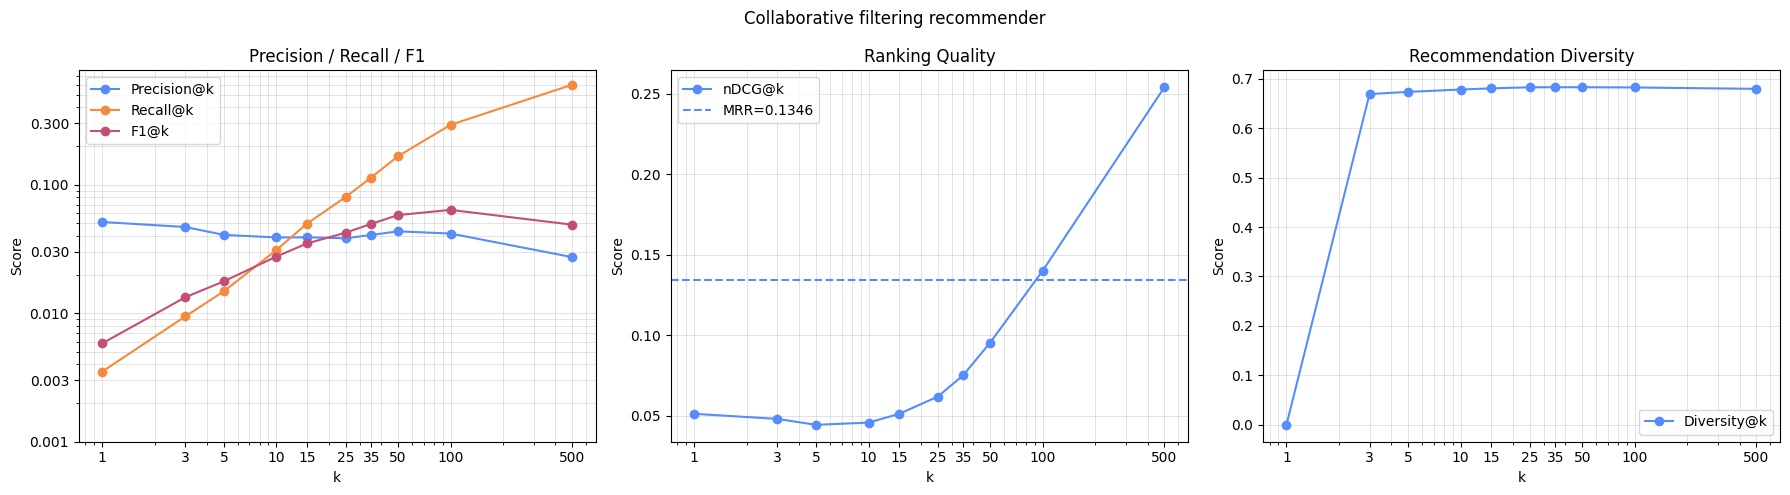

In [28]:
reload(eval)

eval.plot_results_2(results=res, title="Collaborative filtering recommender")


## Hybrid recommender

## Content based then collab filtering

In [52]:
import src.hybrid as h

import src.evaluation as eval

from importlib import reload

reload(eval)

hr = h.HybridRec(
    cbr=cbr,
    cfr=cfr,
    use_content_first=True,
    enlarge_candidate_pool_times=3.5,
)

res = eval.evaluate(
    recommender=hr,
    movies_data=movies,
    ratings_data=ratings,
    relevance_threshold=3.5,
    test_size_per_user=0.3,
    seed=42
)

res


{'train_size': 70316,
 'test_size': 30520,
 'dropped_user_ids': [np.int64(54),
  np.int64(150),
  np.int64(214),
  np.int64(333),
  np.int64(442)],
 'below_required_recommendations': 0,
 'train_duration': datetime.timedelta(microseconds=186524),
 'query_time_500': datetime.timedelta(microseconds=187654),
 'ks': [1, 3, 5, 10, 15, 25, 35, 50, 100, 500],
 'precision': [np.float64(0.06611570247933884),
  np.float64(0.0418732782369146),
  np.float64(0.03768595041322314),
  np.float64(0.03404958677685951),
  np.float64(0.030743801652892564),
  np.float64(0.027834710743801658),
  np.float64(0.026162927981109797),
  np.float64(0.024231404958677687),
  np.float64(0.020578512396694212),
  np.float64(0.01365619834710744)],
 'recall': [np.float64(0.005887009547288621),
  np.float64(0.010051068252493823),
  np.float64(0.015619825055025405),
  np.float64(0.027032705371977855),
  np.float64(0.03641534960695375),
  np.float64(0.05312302908709761),
  np.float64(0.06689486674869585),
  np.float64(0.0883

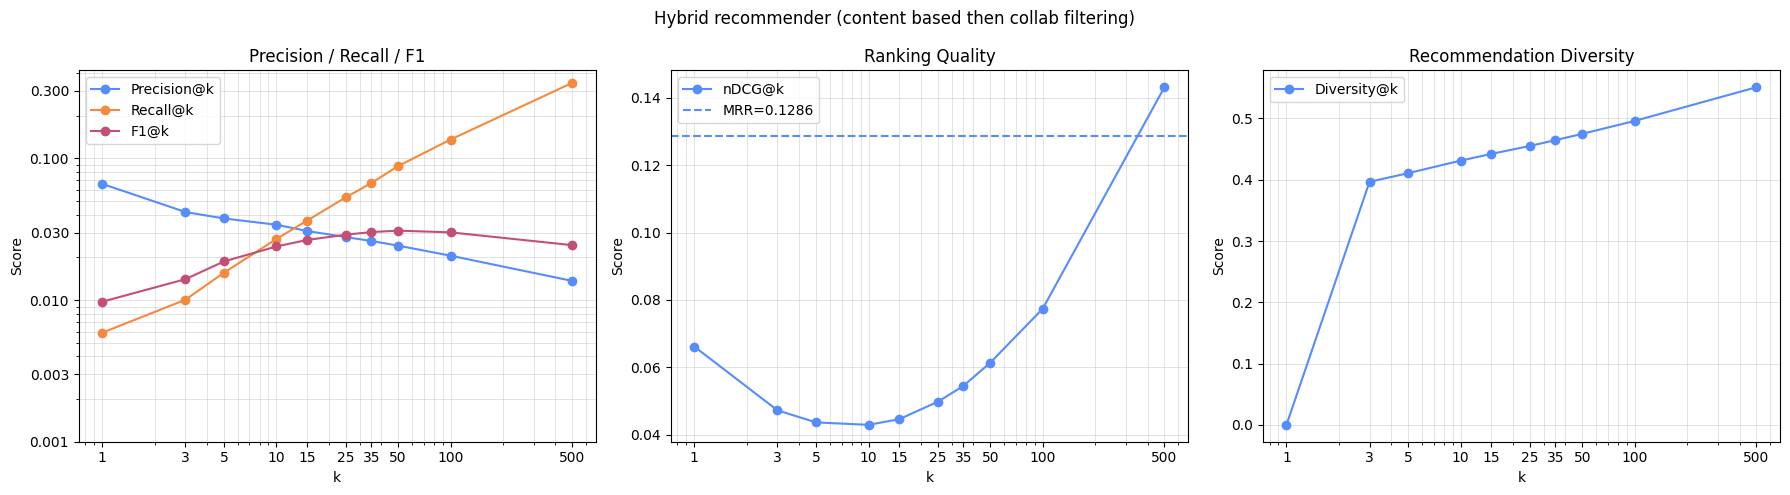

In [53]:
reload(eval)

eval.plot_results_2(results=res, title="Hybrid recommender (content based then collab filtering)")


## Collab filtering then content based

In [54]:
import src.hybrid as h

import src.evaluation as eval

from importlib import reload

reload(eval)

hr = h.HybridRec(
    cbr=cbr,
    cfr=cfr,
    use_content_first=False,
    enlarge_candidate_pool_times=3.5,
)

res = eval.evaluate(
    recommender=hr,
    movies_data=movies,
    ratings_data=ratings,
    relevance_threshold=3.5,
    test_size_per_user=0.3,
    seed=42
)

res



{'train_size': 70316,
 'test_size': 30520,
 'dropped_user_ids': [np.int64(54),
  np.int64(150),
  np.int64(214),
  np.int64(333),
  np.int64(442)],
 'below_required_recommendations': 271,
 'train_duration': datetime.timedelta(microseconds=199272),
 'query_time_500': datetime.timedelta(microseconds=92602),
 'ks': [1, 3, 5, 10, 15, 25, 35, 50, 100, 500],
 'precision': [np.float64(0.09256198347107437),
  np.float64(0.08099173553719008),
  np.float64(0.0806611570247934),
  np.float64(0.07338842975206612),
  np.float64(0.06909090909090909),
  np.float64(0.06737190082644628),
  np.float64(0.0658323494687131),
  np.float64(0.06297520661157024),
  np.float64(0.05514049586776859),
  np.float64(0.029530578512396693)],
 'recall': [np.float64(0.011303292443732184),
  np.float64(0.026406855135221223),
  np.float64(0.039861081648534),
  np.float64(0.06819795438282147),
  np.float64(0.09224774466566774),
  np.float64(0.13631276082696472),
  np.float64(0.17628992800121665),
  np.float64(0.233448903763

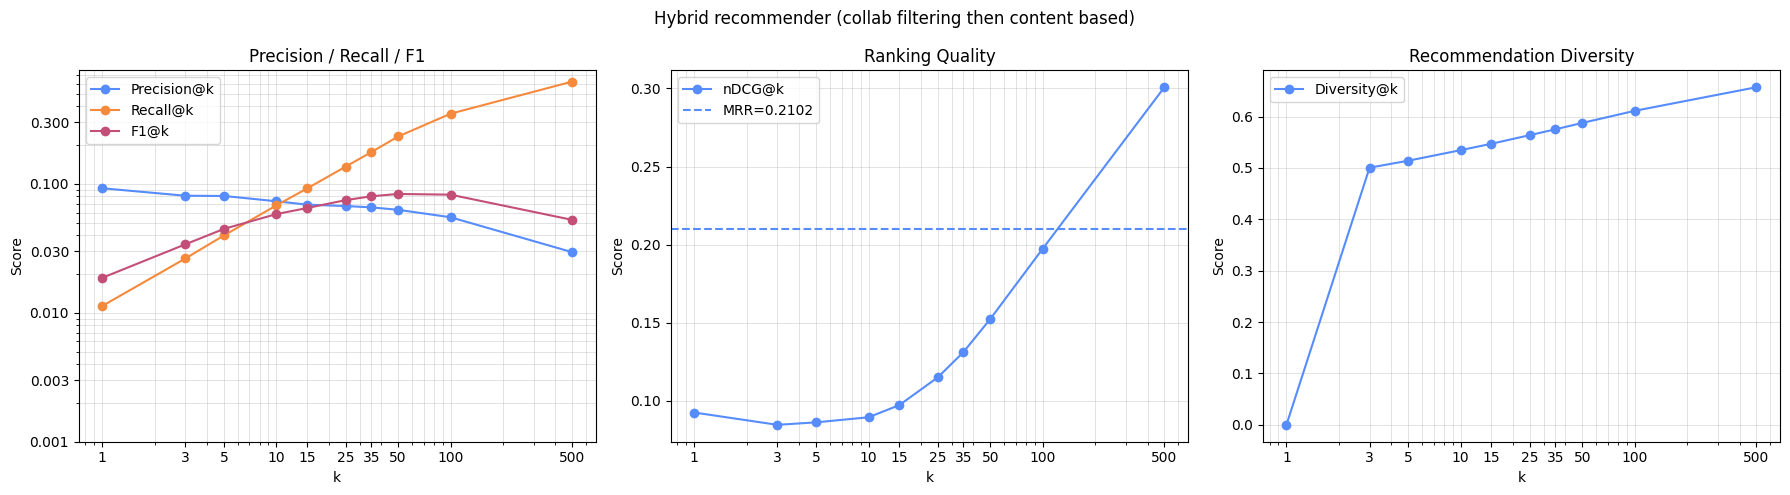

In [55]:
reload(eval)

eval.plot_results_2(results=res, title="Hybrid recommender (collab filtering then content based)")



# TF Framework

In [3]:


import tf_framework as tff
import src.evaluation as eval

from importlib import reload

reload(tff)
reload(eval)


tffr = tff.TfFrameworkRec(
    rating_like_threshold=3.5,
    embedding_dim=64,
    epochs=5,
    batch_size=1024,
    learning_rate=0.05,
    verbose=0,
)



res = eval.evaluate(
    recommender=tffr,
    movies_data=movies,
    ratings_data=ratings,
    relevance_threshold=3.5,
    test_size_per_user=0.3,
    seed=42
)

res


I0000 00:00:1778355829.402804   60749 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1778355829.436582   60749 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1778355830.288238   60749 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1778355830.288441   60749 cudart_stub.cc:31] Could not find cuda drivers on your machine, 

{'train_size': 70316,
 'test_size': 30520,
 'dropped_user_ids': [np.int64(54),
  np.int64(150),
  np.int64(214),
  np.int64(333),
  np.int64(442)],
 'below_required_recommendations': 0,
 'train_duration': datetime.timedelta(seconds=11, microseconds=664266),
 'query_time_500': datetime.timedelta(microseconds=12249),
 'ks': [1, 3, 5, 10, 15, 25, 35, 50, 100, 500],
 'precision': [np.float64(0.14380165289256197),
  np.float64(0.13774104683195593),
  np.float64(0.1252892561983471),
  np.float64(0.11669421487603304),
  np.float64(0.10512396694214875),
  np.float64(0.0924297520661157),
  np.float64(0.08415584415584415),
  np.float64(0.07467768595041323),
  np.float64(0.05849586776859504),
  np.float64(0.025071074380165287)],
 'recall': [np.float64(0.00994950218083531),
  np.float64(0.02785749076800713),
  np.float64(0.04173463474613087),
  np.float64(0.07486633008072623),
  np.float64(0.10033294108602052),
  np.float64(0.1428254441082921),
  np.float64(0.17907005766931164),
  np.float64(0.221

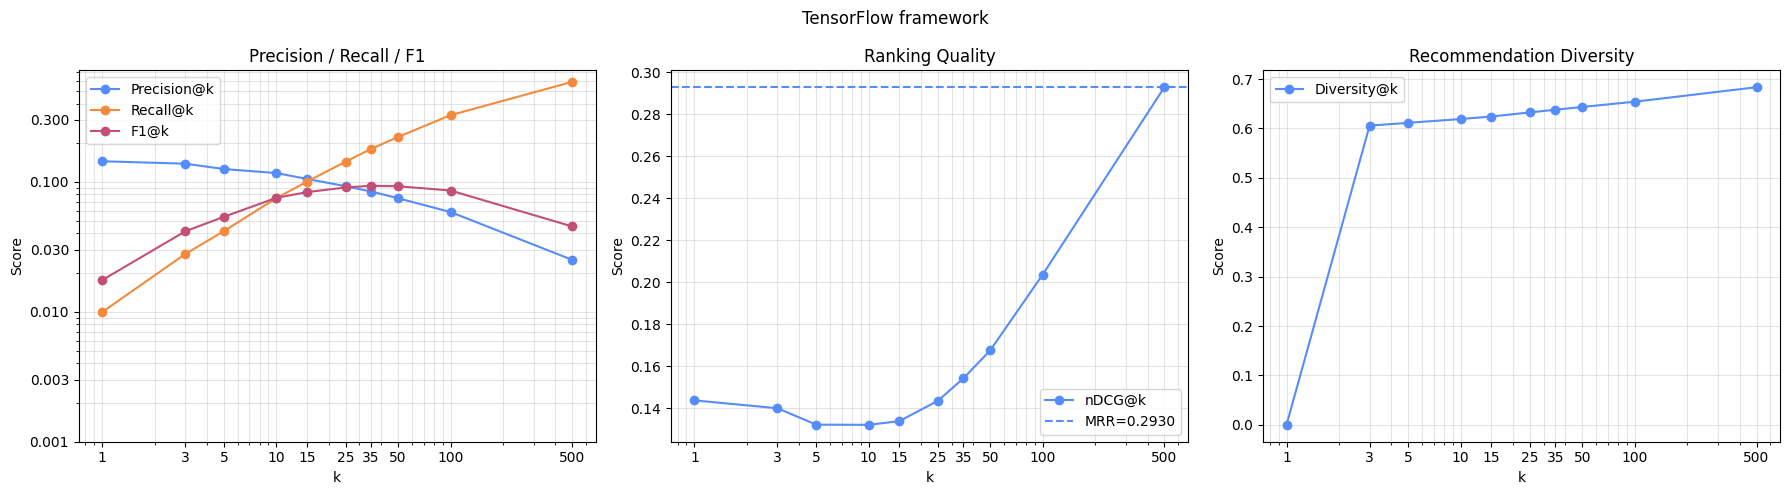

In [4]:
reload(eval)

eval.plot_results_2(results=res, title="TensorFlow framework")


In [8]:
tffr.recommend(1, top_k=10)

,movieId,title,genres,score
1061,1378,Young Guns (1988),Action|Comedy|Western,2.531253
61,69,Friday (1995),Comedy,2.308384
974,1275,Highlander (1986),Action|Adventure|Fantasy,2.270018
1904,2528,Logan's Run (1976),Action|Adventure|Sci-Fi,2.248107
1719,2311,2010: The Year We Make Contact (1984),Sci-Fi,2.241739
856,1127,"Abyss, The (1989)",Action|Adventure|Sci-Fi|Thriller,2.206517
620,785,Kingpin (1996),Comedy,2.206388
858,1129,Escape from New York (1981),Action|Adventure|Sci-Fi|Thriller,2.119409
1231,1639,Chasing Amy (1997),Comedy|Drama|Romance,2.101477
2153,2867,Fright Night (1985),Comedy|Horror|Thriller,1.998299


In [13]:
user_id = 1
relevance_threshold = 3.5
top_k = 10

user_test = ratings[ratings["userId"] == user_id]

relevant_movies = set(user_test[user_test["rating"] >= relevance_threshold]["movieId"])

recommendations = tffr.recommend(user_id, top_k=top_k)
recommendations

,movieId,title,genres,score
1061,1378,Young Guns (1988),Action|Comedy|Western,2.531253
61,69,Friday (1995),Comedy,2.308384
974,1275,Highlander (1986),Action|Adventure|Fantasy,2.270018
1904,2528,Logan's Run (1976),Action|Adventure|Sci-Fi,2.248107
1719,2311,2010: The Year We Make Contact (1984),Sci-Fi,2.241739
856,1127,"Abyss, The (1989)",Action|Adventure|Sci-Fi|Thriller,2.206517
620,785,Kingpin (1996),Comedy,2.206388
858,1129,Escape from New York (1981),Action|Adventure|Sci-Fi|Thriller,2.119409
1231,1639,Chasing Amy (1997),Comedy|Drama|Romance,2.101477
2153,2867,Fright Night (1985),Comedy|Horror|Thriller,1.998299


In [14]:
set(recommendations["movieId"]).intersection(relevant_movies)

{1127, 1275}